# RappiPlus: de datos a decisiones de negocio

## Descripción del proyecto

El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar decisiones de negocio basadas en datos. El análisis trabaja con información de pedidos, catálogo de productos, inversión en marketing, eventos de usuarios, actividad y un experimento de checkout.

El proyecto se organiza en seis etapas: calidad de datos, rentabilidad, funnel de conversión, retención por cohortes, prueba estadística y comunicación de resultados.

## Objetivos

- Revisar la estructura y calidad de los conjuntos de datos.
- Calcular indicadores de ingresos, costos, marketing y ventas.
- Analizar el volumen de usuarios en las etapas del funnel.
- Medir la retención por cohortes mensuales.
- Evaluar las variantes del checkout mediante una prueba Chi-cuadrado.
- Presentar los indicadores de negocio en un dashboard.

## Fuentes de datos

- `rappiplus_orders_raw.csv`: información de pedidos.
- `rappiplus_catalog.csv`: información de productos y costos.
- `rappiplus_marketing_spend.csv`: inversión en marketing.
- `events`: eventos de comportamiento.
- `users` y `user_activity`: registro y actividad de usuarios.
- `experiment_checkout_ui.csv`: datos del experimento de checkout.

## Herramientas

Python · Pandas · Matplotlib · Seaborn · SQL · PostgreSQL · SQLAlchemy · Power BI / Tableau

> **Nota de documentación:** esta versión está preparada para portafolio. Se conserva el código analítico original, salvo la conexión a la base de datos, que se modificó para no exponer credenciales. Los resultados y conclusiones deben corresponder a una ejecución real del notebook.


## 1. Preparación y calidad de los datos

### Objetivo

Conocer la estructura de los conjuntos de datos y revisar posibles problemas que puedan afectar los análisis posteriores.

Se inspeccionan dimensiones, tipos de datos, valores faltantes, formatos de fecha, registros duplicados y campos categóricos. También se preparan los archivos limpios para su uso posterior.

In [1]:
# importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [2]:
# cargar archivos
orders = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')
experiment = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

In [3]:
# explorar datasets
orders.info()
print()
orders.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  str    
 1   id_usuario          25100 non-null  str    
 2   fecha_hora_pedido   25100 non-null  str    
 3   pais                24800 non-null  str    
 4   dispositivo         25080 non-null  str    
 5   fuente_referencia   25070 non-null  str    
 6   nombre_producto     25070 non-null  str    
 7   categoria_producto  25020 non-null  str    
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), str(8)
memory usage: 2.3 MB



id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

In [4]:
catalog.info()
print()
catalog.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      str    
 1   categoria_producto  7 non-null      str    
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      str    
dtypes: float64(1), str(3)
memory usage: 356.0 bytes



nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

In [5]:
marketing.info()
print()
marketing.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   str    
 1   pais        1620 non-null   str    
 2   id_campaña  1620 non-null   str    
 3   canal       1519 non-null   str    
 4   gasto       1620 non-null   float64
dtypes: float64(1), str(4)
memory usage: 63.4 KB



fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

In [6]:
print(orders['fecha_hora_pedido'].head())
print(marketing['fecha'].head())

0    2025-05-22
1    2025-06-15
2    2025-05-02
3    2025-06-09
4    2025-03-30
Name: fecha_hora_pedido, dtype: str
0    2025-01-01
1    2025-01-01
2    2025-01-01
3    2025-01-01
4    2025-01-01
Name: fecha, dtype: str


In [7]:
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'], format='%Y-%m-%d')
print(orders['fecha_hora_pedido'].head())
marketing['fecha'] = pd.to_datetime(marketing['fecha'], format='%Y-%m-%d')
print(marketing['fecha'].head())

0   2025-05-22
1   2025-06-15
2   2025-05-02
3   2025-06-09
4   2025-03-30
Name: fecha_hora_pedido, dtype: datetime64[us]
0   2025-01-01
1   2025-01-01
2   2025-01-01
3   2025-01-01
4   2025-01-01
Name: fecha, dtype: datetime64[us]


In [8]:
# Cuántos nulos hay en total en esa columna
print(marketing['canal'].isna().sum())

# Ver todas las filas donde 'canal' es nulo
print(marketing[marketing['canal'].isna()])

# Ver si hay otros "nulos disfrazados" como texto (por si acaso)
print(marketing['canal'].value_counts(dropna=False))

101
         fecha       pais             id_campaña canal    gasto
98  2025-01-11  Argentina       social_Argentina   NaN   849.70
99  2025-01-12     Mexico         organic_Mexico   NaN  2033.56
100 2025-01-12     Mexico     paid_search_Mexico   NaN  1260.65
101 2025-01-12     Mexico          social_Mexico   NaN  1660.90
102 2025-01-12   Colombia       organic_Colombia   NaN  1819.27
..         ...        ...                    ...   ...      ...
194 2025-01-22   Colombia        social_Colombia   NaN   772.46
195 2025-01-22  Argentina      organic_Argentina   NaN  1562.61
196 2025-01-22  Argentina  paid_search_Argentina   NaN   644.34
197 2025-01-22  Argentina       social_Argentina   NaN  2544.66
198 2025-01-23     Mexico         organic_Mexico   NaN  2977.84

[101 rows x 5 columns]
canal
paid_search    507
organic        506
social         506
NaN            101
Name: count, dtype: int64


In [9]:
nulos_canal = marketing[marketing['canal'].isnull()]
print(nulos_canal['id_campaña'].value_counts)

<bound method IndexOpsMixin.value_counts of 98          social_Argentina
99            organic_Mexico
100       paid_search_Mexico
101            social_Mexico
102         organic_Colombia
               ...          
194          social_Colombia
195        organic_Argentina
196    paid_search_Argentina
197         social_Argentina
198           organic_Mexico
Name: id_campaña, Length: 101, dtype: str>


In [10]:
marketing[(marketing['canal'].isna()) & (marketing['pais'] == 'Mexico')]
marketing[(marketing['canal'].isna()) & (marketing['pais'] == 'Colombia')]
marketing[(marketing['canal'].isna()) & (marketing['pais'] == 'Argentina')]

,fecha,pais,id_campaña,canal,gasto
98,2025-01-11,Argentina,social_Argentina,NaN,849.70
105,2025-01-12,Argentina,organic_Argentina,NaN,1860.40
106,2025-01-12,Argentina,paid_search_Argentina,NaN,885.06
107,2025-01-12,Argentina,social_Argentina,NaN,2253.77
114,2025-01-13,Argentina,organic_Argentina,NaN,833.13
115,2025-01-13,Argentina,paid_search_Argentina,NaN,2961.96
116,2025-01-13,Argentina,social_Argentina,NaN,2797.14
123,2025-01-14,Argentina,organic_Argentina,NaN,1095.33
124,2025-01-14,Argentina,paid_search_Argentina,NaN,2189.47
125,2025-01-14,Argentina,social_Argentina,NaN,2631.69


In [11]:
marketing_sin_nulos = marketing['canal'].dropna()
print(marketing_sin_nulos.isna().sum())

0


In [12]:


print(f"Filas antes: {len(orders)}")
orders = orders.drop_duplicates(subset=['id_pedido'], keep='first')
orders = orders.dropna()
print(f"Filas después: {len(orders)}")



Filas antes: 25100
Filas después: 24600


In [13]:
print(f"Filas antes: {len(marketing)}")
marketing = marketing.dropna(subset=['canal'])
print(f"Filas después: {len(marketing)}")

Filas antes: 1620
Filas después: 1519


In [14]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

In [15]:
catalog.isna().sum()

nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

In [16]:
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [17]:
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [18]:
marketing.head(10)

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40
5,2025-01-01,Colombia,social_Colombia,social,833.38
6,2025-01-01,Argentina,organic_Argentina,organic,1365.62
7,2025-01-01,Argentina,paid_search_Argentina,paid_search,1282.65
8,2025-01-01,Argentina,social_Argentina,social,1534.69
9,2025-01-02,Mexico,organic_Mexico,organic,2537.38


### Observaciones de calidad de datos

Al ejecutar esta sección, documentar los cambios realizados y su efecto en los datos: registros duplicados eliminados, filas excluidas por valores faltantes y formatos de fecha convertidos. Es importante considerar que la exclusión de registros puede modificar los totales calculados en las siguientes etapas.

Los archivos exportados (`orders_clean.csv`, `catalog_clean.csv` y `marketing_clean.csv`) se utilizan posteriormente para el análisis y el dashboard.

## 2. Rentabilidad y comportamiento de ventas

### Objetivo

Calcular indicadores que permitan describir los ingresos, los costos de producto, la inversión en marketing y algunos aspectos del comportamiento de compra.

### Indicadores analizados

- Ingreso total.
- Costo total de los productos vendidos.
- Inversión total en marketing.
- Ganancia calculada.
- Ticket promedio.
- Cantidad promedio de productos comprados.
- Producto con mayor cantidad vendida.
- Inversión por canal de marketing.

> **Alcance de la ganancia:** en este proyecto se calcula restando al ingreso el costo de los productos y el gasto de marketing. Esta métrica no debe interpretarse como utilidad neta contable, ya que no incorpora otros posibles gastos del negocio.


In [19]:
ingreso_total = orders['monto_total'].sum()
print(f"ingreso total: {ingreso_total.round(2)}")


ingreso total: 51836375.14


In [20]:
# Unir orders con catalog usando el nombre del producto como clave
merged = orders.merge(catalog, on='nombre_producto')

# Calcular el costo total por cada línea de la orden
merged['costo_total'] = merged['costo_unitario'] * merged['cantidad']

# Sumar todo para obtener el costo total general
costo_total_general = merged['costo_total'].sum()
print(f"\nCosto total de productos vendidos: {costo_total_general}")


Costo total de productos vendidos: 43078678.800000004


In [21]:
gasto_marketing = marketing['gasto'].sum()
print(f"Gasto total de marketing: {gasto_marketing:.2f}")

Gasto total de marketing: 2694664.43


In [22]:
ganancia = ingreso_total - costo_total_general - gasto_marketing
print(f"Ganancia: {ganancia:.2f} ")

Ganancia: 6063031.91 


In [23]:
precio_promedio = orders['monto_total'].mean()
print(f"Ticket promedio : {precio_promedio:.2f}")

Ticket promedio : 2107.17


In [24]:
cantidad_promedio = orders['cantidad'].mean()
print(f"Cantidad de productos comprados promedio : {cantidad_promedio:.2f}")

Cantidad de productos comprados promedio : 7.20


In [25]:
producto_mas_vendido = orders.groupby('nombre_producto')['cantidad'].sum().idxmax()
print(f"producto mas vendido: {producto_mas_vendido}")

producto mas vendido: Laptop-Gaming-16GB


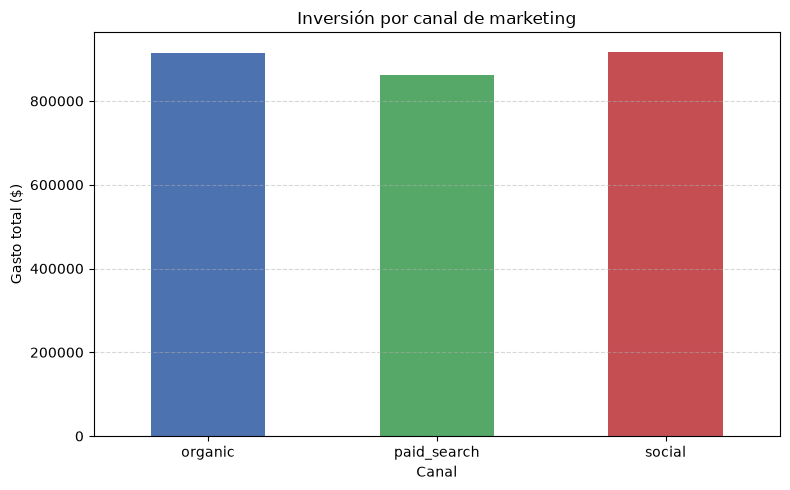

In [26]:
total_de_inversion_por_canal = marketing.groupby('canal')['gasto'].sum()

plt.figure(figsize=(8, 5))
total_de_inversion_por_canal.plot(kind='bar', color=['#4C72B0', '#55A868', '#C44E52'])
plt.title('Inversión por canal de marketing')
plt.xlabel('Canal')
plt.ylabel('Gasto total ($)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretación de resultados

Completar esta sección con los valores obtenidos al ejecutar el notebook. Comparar ingresos, costos e inversión; describir el ticket promedio y la cantidad promedio; identificar el producto con mayor volumen vendido y comentar qué canal concentra la inversión más alta.

Las conclusiones deben describir lo que muestran los datos, sin atribuir causalidad a relaciones que este análisis no demuestra.

## 3. Funnel de conversión

### Objetivo

Analizar cuántos usuarios únicos llegan a cada etapa del proceso de compra y observar cómo cambia el volumen entre eventos.

El análisis utiliza la tabla `events` y considera las etapas `first_visit`, `add_to_cart`, `select_item`, `begin_checkout`, `add_payment_info` y `purchase`.

### Conexión a PostgreSQL

La conexión utiliza una variable de entorno para evitar almacenar credenciales dentro del notebook. Configura `DATABASE_URL` localmente en un archivo `.env`, que debe permanecer fuera del repositorio público.

In [27]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql+psycopg2://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [28]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [29]:
events['nombre_evento'].unique()

<StringArray>
[     'first_visit',      'add_to_cart', 'add_payment_info',
         'purchase',   'begin_checkout',      'select_item']
Length: 6, dtype: str

In [30]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT nombre_evento, COUNT(DISTINCT id_usuario) as usuarios_unicos
FROM events
GROUP BY nombre_evento
ORDER BY usuarios_unicos DESC;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,first_visit,7796
1,add_to_cart,7634
2,select_item,7582
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


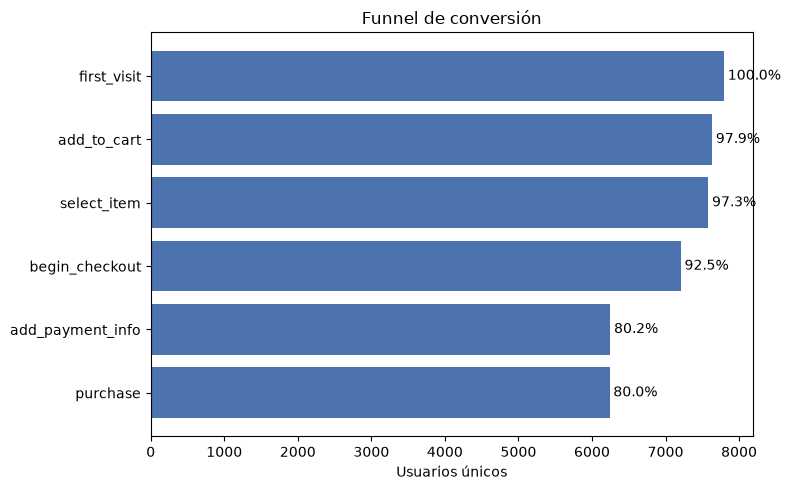

In [31]:
# PARTE 2: Conversiones
# ======================
query_conversion = '''
WITH funnel AS (
    SELECT 
        nombre_evento, 
        COUNT(DISTINCT id_usuario) AS usuarios_unicos,
        CASE
            WHEN nombre_evento = 'first_visit' THEN 0
            WHEN nombre_evento = 'add_to_cart' THEN 1
            WHEN nombre_evento = 'select_item' THEN 2
            WHEN nombre_evento = 'begin_checkout' THEN 3
            WHEN nombre_evento = 'add_payment_info' THEN 4
            WHEN nombre_evento = 'purchase' THEN 5
        END AS orden_funnel
    FROM events
    GROUP BY nombre_evento
)
SELECT
    nombre_evento,
    usuarios_unicos,
    orden_funnel,
    -- Conversión respecto al paso INMEDIATAMENTE anterior
    ROUND(
        100.0 * usuarios_unicos 
        / LAG(usuarios_unicos) OVER (ORDER BY orden_funnel), 
        2
    ) AS conversion_paso_anterior_pct,
    -- Conversión respecto al PRIMER paso del funnel (acumulada)
    ROUND(
        100.0 * usuarios_unicos 
        / FIRST_VALUE(usuarios_unicos) OVER (ORDER BY orden_funnel), 
        2
    ) AS conversion_total_pct
FROM funnel
ORDER BY orden_funnel;
'''

conversion = pd.read_sql(query_conversion, con=engine)

plt.figure(figsize=(8, 5))
plt.barh(conversion['nombre_evento'], conversion['usuarios_unicos'], color='#4C72B0')
plt.gca().invert_yaxis()  # para que el primer paso quede arriba
plt.xlabel('Usuarios únicos')
plt.title('Funnel de conversión')

# Agregar etiquetas con el % de conversión total
for i, (usuarios, pct) in enumerate(zip(conversion['usuarios_unicos'], conversion['conversion_total_pct'])):
    plt.text(usuarios + 50, i, f"{pct:.1f}%", va='center')

plt.tight_layout()
plt.show()

### Interpretación del funnel

Revisar el número de usuarios únicos por evento, identificar la etapa con la mayor disminución y comentar las tasas de conversión calculadas por la consulta.

**Alcance:** los conteos agregados de usuarios únicos por evento no demuestran por sí solos que cada usuario haya recorrido las etapas en ese orden individualmente. Las tasas deben interpretarse como relaciones entre los conteos agregados de las etapas.

## 4. Retención por cohortes

### Objetivo

Analizar la actividad de los usuarios después de su registro, agrupándolos según el mes en que se registraron.

Se utilizan las tablas `users` y `user_activity`. La consulta calcula la actividad en los días 7, 14 y 21 posteriores al registro y presenta los resultados por cohorte mensual.

In [32]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [33]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head()

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1
3,user_0,2025-02-26,28,0
4,user_1,2025-01-14,7,0


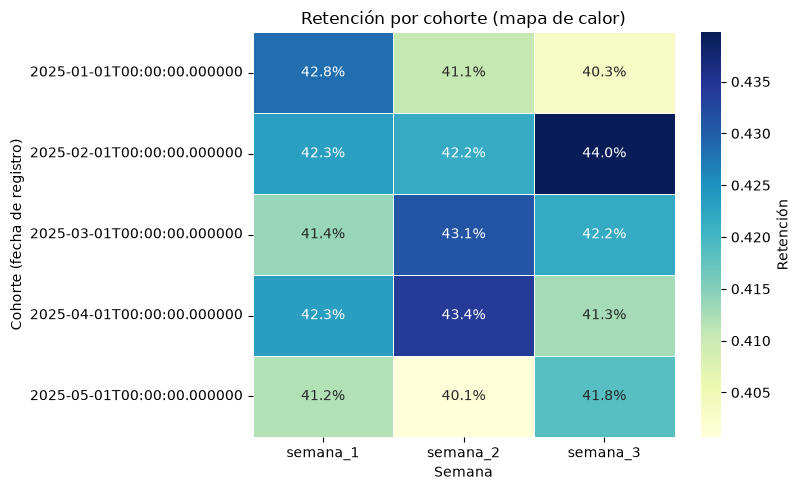

In [34]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH T_orders AS(
    SELECT 
    id_usuario,
    fecha_registro, 
    DATE_TRUNC('month', CAST(fecha_registro as DATE)) as T_fecha_registro
FROM users
)
SELECT 
    T_O.T_fecha_registro,
    AVG(CASE WHEN dias_despues_registro = 7 THEN activo END) AS semana_1,
    AVG(CASE WHEN dias_despues_registro = 14 THEN activo END) AS semana_2,
    AVG(CASE WHEN dias_despues_registro = 21 THEN activo END) AS semana_3
FROM T_orders AS T_O
JOIN user_activity AS U_A ON T_O.id_usuario = U_A.id_usuario
GROUP BY T_fecha_registro
ORDER BY T_fecha_registro 
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)

heatmap_data = cohorte_final.set_index('t_fecha_registro')[['semana_1', 'semana_2', 'semana_3']]

plt.figure(figsize=(8, 5))
sns.heatmap(
    heatmap_data,
    annot=True,          # muestra el valor numérico en cada celda
    fmt=".1%",           # formatea como porcentaje con 1 decimal
    cmap="YlGnBu",        # escala de color (más oscuro = mayor retención)
    linewidths=0.5,
    cbar_kws={'label': 'Retención'}
)

plt.title('Retención por cohorte (mapa de calor)')
plt.xlabel('Semana')
plt.ylabel('Cohorte (fecha de registro)')
plt.tight_layout()
plt.show()

### Interpretación de retención

Comparar los porcentajes de retención entre cohortes y observar cómo cambian entre la primera, segunda y tercera semana. Señalar los patrones visibles en la tabla o el mapa de calor, considerando que el tamaño de cada cohorte y el periodo de observación pueden influir en la comparación.

## 5. Experimento A/B: conversión del checkout

### Objetivo

Evaluar si existe evidencia estadística de una diferencia en la conversión entre las variantes del checkout, utilizando el conjunto `experiment_checkout_ui.csv`.

### Hipótesis

- **H₀:** no existe asociación entre la variante del checkout y el resultado de conversión.
- **H₁:** existe asociación entre la variante del checkout y el resultado de conversión.

**Prueba estadística:** Chi-cuadrado de independencia.  
**Nivel de significancia:** α = 0.05.

In [35]:
experiment.info()
experiment.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  str    
 1   variante         10000 non-null  str    
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  str    
 4   pais             10000 non-null  str    
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  str    
dtypes: float64(1), int64(1), str(5)
memory usage: 547.0 KB


id_usuario         0
variante           0
convirtio          0
dispositivo        0
pais               0
duracion_sesion    0
timestamp          0
dtype: int64

In [36]:
experiment.head(10)

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12
5,exp_user_5,control,0,mobile,Mexico,206.70,2025-01-26
6,exp_user_6,control,0,desktop,Mexico,280.11,2025-04-15
7,exp_user_7,tratamiento,0,mobile,Argentina,28.47,2025-03-18
8,exp_user_8,tratamiento,0,desktop,Mexico,287.04,2025-02-05
9,exp_user_9,control,0,mobile,Argentina,258.91,2025-02-11


In [37]:
resumen = experiment.groupby('variante')['convirtio'].agg(
    total_usuarios='count',
    conversiones='sum'
).reset_index()

resumen['tasa_conversion_%'] = (resumen['conversiones'] / resumen['total_usuarios'] * 100).round(2)

print(resumen)

      variante  total_usuarios  conversiones  tasa_conversion_%
0      control            4965           779              15.69
1  tratamiento            5035           820              16.29


In [38]:
# Tabla de contingencia: variante vs convirtio
tabla_contingencia = pd.crosstab(experiment['variante'], experiment['convirtio'])
print(tabla_contingencia)

# Test chi-cuadrado
chi2, p_valor, gl, esperado = chi2_contingency(tabla_contingencia)

print(f"\nChi2: {chi2:.4f}")
print(f"p-valor: {p_valor:.4f}")
print(f"Grados de libertad: {gl}")
print(f"\nFrecuencias esperadas:\n{esperado}")

# Interpretación
alpha = 0.05
if p_valor < alpha:
    print(f"\n Hay diferencia significativa entre variantes (p={p_valor:.4f} < {alpha})")
else:
    print(f"\n No hay evidencia suficiente de diferencia significativa (p={p_valor:.4f} >= {alpha})")
print(f"\n tenemos un valor p muy alto lo que representa que no tenemos datos correctos debido a la gran variacion en los clientes")

convirtio       0    1
variante              
control      4186  779
tratamiento  4215  820

Chi2: 0.6178
p-valor: 0.4319
Grados de libertad: 1

Frecuencias esperadas:
[[4171.0965  793.9035]
 [4229.9035  805.0965]]

 No hay evidencia suficiente de diferencia significativa (p=0.4319 >= 0.05)

 tenemos un valor p muy alto lo que representa que no tenemos datos correctos debido a la gran variacion en los clientes


### Interpretación estadística

Comparar el valor p con el nivel de significancia de 0.05:

- Si `p_valor < 0.05`, se rechaza H₀ y existe evidencia estadística de asociación entre la variante y la conversión.
- Si `p_valor >= 0.05`, no se rechaza H₀; no hay evidencia suficiente para afirmar que exista una diferencia estadísticamente significativa.

No rechazar H₀ no demuestra que las variantes sean idénticas. La interpretación también debe considerar las tasas observadas, el tamaño de muestra y las frecuencias esperadas.

## 6. Comunicación de resultados: dashboard en BI

### Objetivo

Presentar de forma visual los indicadores de ventas, costos, marketing y conversión para facilitar su consulta.

Los archivos limpios generados en la primera etapa son:
- `orders_clean.csv`
- `catalog_clean.csv`
- `marketing_clean.csv`

### Vista ejecutiva

Indicadores que pueden incluirse:
- Revenue total.
- Profit calculado.
- Gasto total en marketing.
- Ticket promedio.
- Cantidad promedio de productos por orden.

Visualizaciones contempladas:
- Tarjetas KPI para revenue, profit y gasto de marketing.
- Evolución mensual de revenue o profit.
- Comparación de indicadores por periodo, si los datos lo permiten.
- Comparación de revenue y profit por producto o categoría.

### Vista de detalle

- Tabla de órdenes con producto, cantidad, revenue, costo y profit.
- Formato condicional para distinguir resultados positivos y negativos.
- Cantidad vendida por producto.
- Navegación de detalle por producto (drill-through).
- Filtros por fecha y categoría, cuando los campos estén disponibles.

**Enlace del dashboard:** pendiente de agregar cuando exista una publicación accesible.

## 7. Conclusiones y recomendaciones

Completar este apartado con hallazgos respaldados por los resultados del notebook y del dashboard.

1. **Calidad de datos:** resumir los problemas encontrados y los tratamientos aplicados.
2. **Rentabilidad:** interpretar ingresos, costos, inversión en marketing y ganancia calculada.
3. **Conversión:** describir las principales variaciones entre etapas del funnel.
4. **Retención:** comparar los resultados entre cohortes y semanas.
5. **Experimento:** comunicar el resultado de la prueba Chi-cuadrado y sus limitaciones.

Las recomendaciones deben derivarse de los resultados observados. Diferenciar los hallazgos comprobados de las hipótesis que necesitarían análisis adicional.

## 8. Reproducibilidad y consideraciones

- Ejecutar las celdas en orden.
- La carga de los archivos CSV requiere conexión a internet.
- Las secciones de funnel y retención requieren acceso autorizado a PostgreSQL.
- Configurar `DATABASE_URL` en un archivo `.env` local.
- No subir credenciales, contraseñas ni el archivo `.env` a GitHub.
- Los resultados pueden cambiar si cambian las fuentes de datos.
- El dashboard de Power BI o Tableau es un entregable separado; agregar el enlace cuando esté publicado.
